In [3]:
import numpy as np

from matplotlib import pyplot as plt

# Use TeX
from matplotlib import rc
rc('font', size=18)
rc('text', usetex=True)
rc('font', family='serif')

from matplotlib import colormaps
cmap_default = colormaps['viridis'].with_extremes(under='k')
cmap_default.set_bad(color='black')

from lenstronomy.SimulationAPI.sim_api import SimAPI
from lenstronomy.SimulationAPI.ObservationConfig.HST import HST

In [31]:
# source

source_model_list = ['SERSIC_ELLIPSE']

magnitude_source = 24.0

R_sersic_source = 0.1
n_sersic_source = 3.0
e1_source = 0.0
e2_source = 0.0
x_source = 0.0
y_source = 0.0

kwargs_sersic = {'magnitude': magnitude_source,
                 'R_sersic': R_sersic_source, 
                 'n_sersic': n_sersic_source, 
                 'e1': e1_source, 
                 'e2': e2_source, 
                 'center_x': x_source, 
                 'center_y': y_source}

kwargs_source_mag = [kwargs_sersic]

# lens: EPL
image_lens_model_list = ['EPL']
kwargs_EPL = {'theta_E': 1.5, 'gamma': 2.0, 'e1': 0.0, 'e2': 0.0}
kwargs_lens = [kwargs_EPL]
profile_kwargs_list = [None]

# gather the full model
kwargs_model = {'lens_model_list': image_lens_model_list,
                'lens_profile_kwargs_list': profile_kwargs_list,
                'source_light_model_list': source_model_list}

# get the telescope settings for HST
psf = 'GAUSSIAN'
band = HST(band='WFC3_F160W', psf_type=psf) # this chooses the specific camera and filter of HST
kwargs_band = band.kwargs_single_band() # we are only considering a single band (i.e. a single wavelength/filter)
pixel_size = band.camera['pixel_scale'] # in arcsec

kwargs_psf = {'psf_type': psf,
              'fwhm': kwargs_band['seeing'],
              'pixel_size': pixel_size,
              'truncation': 5}

# define the numerics
kwargs_numerics = {'supersampling_factor': 1,
                   'supersampling_convolution': False}

# call the simulation API class
sim = SimAPI(num_pix = 113, # number of pixels we want in our image
             kwargs_single_band = kwargs_band, # give the SimAPI class the keyword arguments for HST that we got above
             kwargs_model = kwargs_model)

kwargs_data = sim.kwargs_data

# convert magnitudes into amplitudes
# we don't care about lens light or point source for the moment
_, kwargs_source, _ = sim.magnitude2amplitude(kwargs_source_mag=kwargs_source_mag)

# now use the SimAPI class to generate a noisy image in one step
imSim = sim.image_model_class(kwargs_numerics)

image = imSim.image(kwargs_lens = kwargs_lens,
                    kwargs_source = kwargs_source)

image_noisy = image + sim.noise_for_model(model = image)

kwargs_data['image_data'] = image_noisy

In [32]:
1.5 * 6 / pixel_size

112.5

In [33]:
sim.flux_noise(1)

np.float64(0.013608276348795434)

/var/folders/pp/t8q3hnyx3ll7kcn8h_02ghfw0000gp/T/ipykernel_73342/1110232551.py:11: RuntimeWarning: invalid value encountered in log10
  im = ax.matshow(np.log10(image_noisy), origin='lower', vmin=v_min, vmax=v_max, cmap=cmap, extent=[0, 1, 0, 1])


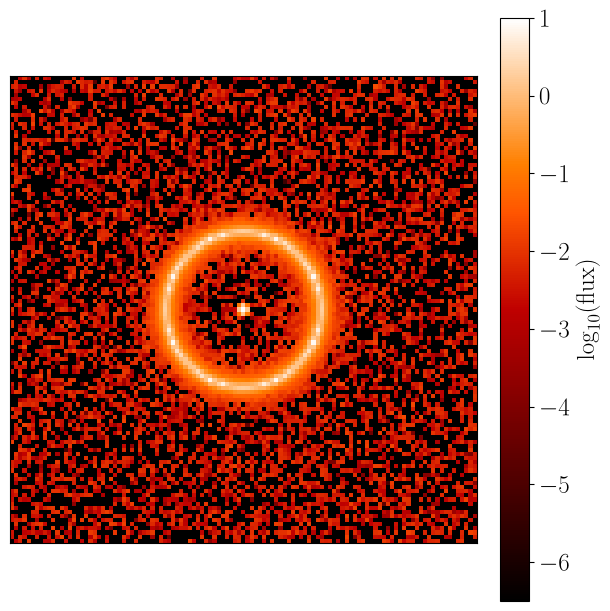

In [34]:
# plot the image
cmap_string = 'gist_heat'
cmap = plt.get_cmap(cmap_string).copy()
cmap.set_bad(color='k', alpha=1.)
cmap.set_under('k')

v_min = -6.5
v_max = 1

f, ax = plt.subplots(1, 1, figsize=(6, 6), sharex=False, sharey=False, layout='constrained')
im = ax.matshow(np.log10(image_noisy), origin='lower', vmin=v_min, vmax=v_max, cmap=cmap, extent=[0, 1, 0, 1])
ax.get_xaxis().set_visible(False)
ax.get_yaxis().set_visible(False)
f.colorbar(im, ax=ax, label=r'$\log_{10}(\mathrm{flux})$')
ax.autoscale(False)

plt.show()

In [6]:
kwargs_source

[{'R_sersic': 0.03,
  'n_sersic': 1.0,
  'e1': 0.3,
  'e2': 0.0,
  'center_x': 0.1,
  'center_y': 0.1,
  'amp': np.float64(564.8307247876069)}]

In [35]:
def density(theta, N, theta_E, theta_max):

    return N / 2 / np.pi / theta_max / theta_E

In [37]:
theta_E = 1.5
theta_max = 4 * theta_E
N = 1e6

n_E = density(theta=theta_E, N=N, theta_E=theta_E, theta_max=theta_max)
theta_c = 1/np.sqrt(n_E)

print(theta_c)

0.007519884823893002
